# 09 · FastText dari korpus ke embedding

**Tujuan:** Memperlihatkan training lokal, kata/subkata, pooling vektor, cosine, dan inspeksi kualitas.

**Alur:** input → proses yang terlihat → pengecekan → output. Semua label kompetensi lama hanya dipakai sebagai referensi audit, bukan kebenaran relevansi.

## 0. Setup dan validasi sumber data

In [1]:
from pathlib import Path
import os, sys, json, time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT/'data'/'dataset_buku_2000.csv').exists(): ROOT=ROOT.parent
assert (ROOT/'data'/'dataset_buku_2000.csv').exists(), f'Folder proyek tidak ditemukan dari {Path.cwd()}'
sys.path.insert(0,str(ROOT))
from src import engine
DATA, OUT, FIG, MODELS = [ROOT/x for x in ('data','outputs','figures','models')]
for folder in (OUT,FIG,MODELS): folder.mkdir(exist_ok=True)
books, comps = engine.load_data()
print('Dataset:',len(books),'buku;',len(comps),'kompetensi')
assert books.book_id.is_unique and comps.competency_id.is_unique

Dataset: 973 buku; 67 kompetensi


## 1. Input yang sama

In [2]:
clean=pd.read_csv(OUT/'dataset_buku_bersih.csv',dtype=str).fillna('')
profiles=pd.read_csv(OUT/'profil_kompetensi_query.csv',dtype=str).fillna('')
assert len(clean)==len(books) and len(profiles)==len(comps)
books['teks_buku']=clean.set_index('book_id').reindex(books.book_id)['teks_model'].fillna('').to_numpy() if 'teks_model' in clean.columns else books.teks_buku
comps['teks_query']=profiles.set_index('competency_id').reindex(comps.competency_id)['teks_query'].fillna('').to_numpy() if 'teks_query' in profiles.columns else comps.teks_query
assert books.teks_buku.str.len().gt(0).all()
print('Contoh buku:',books[['judul','teks_buku']].head(2).to_string(index=False,max_colwidth=110))
print('Contoh kompetensi:',comps[['competency_name','teks_query']].head(2).to_string(index=False,max_colwidth=110))

Contoh buku:                                judul                                                                                                      teks_buku
            Business Growth Strategy Business Growth Strategy Business Growth Strategy Introduction I wrote this book, “Business Growth Strategy...
Mastering Business Growth Strategies Mastering Business Growth Strategies Mastering Business Growth Strategies Mastering Business Growth Strateg...
Contoh kompetensi:      competency_name                                                                          teks_query
Business Development       Business Development business growth; business strategy; market opportunities
Marketing Management Marketing Management marketing strategy; marketing analytics; customer segmentation


## 2. Bangun token kalimat dari katalog

Model lokal dari 973 dokumen ini hanya baseline, tidak dianggap setara model pretrained besar.

In [3]:
from gensim.models import FastText
from gensim.utils import simple_preprocess
from sklearn.preprocessing import normalize
corpus=[simple_preprocess(text) for text in books.teks_buku]
print('Jumlah dokumen:',len(corpus),'contoh token:',corpus[0][:30])
print('Panjang median token:',np.median([len(x) for x in corpus]))

Jumlah dokumen: 973 contoh token: ['business', 'growth', 'strategy', 'business', 'growth', 'strategy', 'introduction', 'wrote', 'this', 'book', 'business', 'growth', 'strategy', 'to', 'help', 'entrepreneurs', 'learn', 'how', 'to', 'grow', 'their', 'business', 'and', 'use', 'the', 'best', 'strategies', 'as', 'you', 'read']
Panjang median token: 139.0


## 3. Training FastText beserta parameter

Parameter eksplisit dan seed tetap untuk reprodusibilitas.

In [4]:
# Training ulang dari awal, kecuali nanti pengguna sengaja memilih memuat model tersimpan.
# Untuk eksperimen baru, ubah TRAIN_ULANG=True agar pelatihan dijalankan lagi.
TRAIN_ULANG = True
model_path = MODELS/'fasttext.model'
t0=time.perf_counter()
if model_path.exists() and not TRAIN_ULANG:
    model = FastText.load(str(model_path))
    print('Model FastText tersimpan dibuka; training tidak diulang.')
else:
    model=FastText(vector_size=80,window=5,min_count=1,workers=1,sg=1,seed=42)
    model.build_vocab(corpus_iterable=corpus)
    print('Vocabulary:',len(model.wv),'jumlah dokumen:',model.corpus_count)
    model.train(corpus_iterable=corpus,total_examples=model.corpus_count,epochs=8)
    model.save(str(model_path))
    print('Model baru dilatih dan disimpan.')
print('Persiapan model (detik):',round(time.perf_counter()-t0,2))

Vocabulary: 10630 jumlah dokumen: 973
Model baru dilatih dan disimpan.
Persiapan model (detik): 19.05


## 4. Lihat embedding dan uji pooling

Rata-rata vektor kata dapat kehilangan istilah kunci; ini keterbatasan baseline.

In [5]:
def document_vector(text):
    tokens=simple_preprocess(text)
    return np.mean([model.wv[w] for w in tokens],axis=0) if tokens else np.zeros(80)
sample_word=corpus[0][0] if corpus[0] else 'risk'
print('Contoh kata:',sample_word,'dimensi vektor:',model.wv[sample_word].shape)
print('Vektor 8 angka pertama:',model.wv[sample_word][:8])
B=normalize(np.stack([document_vector(t) for t in books.teks_buku]))
C=normalize(np.stack([document_vector(t) for t in comps.teks_query]))
print('Bentuk matriks embedding buku:',B.shape,'kompetensi:',C.shape)

Contoh kata: business dimensi vektor: (80,)
Vektor 8 angka pertama: [ 0.49851817 -0.21499585 -0.36642158 -0.16199729  0.37795198 -0.00537357
  0.14207152 -0.0138932 ]
Bentuk matriks embedding buku: (973, 80) kompetensi: (67, 80)


## 5. Hitung similarity, pemeriksaan kualitas, simpan

FastText Top 10 wajib diaudit isi abstraknya; nilai cosine tinggi bukan jaminan relevansi.

,ranking,judul,skor_asli
0,1,Emerging Business Opportunities in Africa: Mar...,0.926449
1,2,Mastering Business Strategy,0.924993
2,3,Strategic Purchasing and Supply Management,0.922505
3,4,Strategic Procurement Management for Competiti...,0.916193
4,5,Business Ethics,0.915277
5,6,Business Etiquette Today,0.914320
6,7,Wise Growth Strategies in Leading Family Busin...,0.911615
7,8,Business Model Renewal: How to Grow and Prospe...,0.910299
8,9,Mastering Business Growth Strategies,0.906029
9,10,ITIL® 4 Leader Digital and IT Strategy (DITS) ...,0.905876


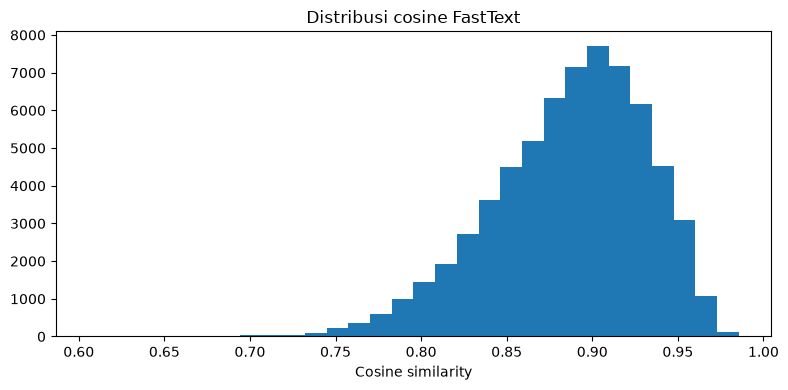

In [6]:
scores=C@B.T;elapsed=time.perf_counter()-t0
pairs,top=engine.save_all_pairs(scores,books,comps,'fasttext')
pd.DataFrame([{'model':'fasttext','waktu_total_detik':elapsed,'jumlah_pasangan':len(pairs)}]).to_csv(OUT/'runtime_fasttext.csv',index=False)
q=top[top.competency_id==comps.competency_id.iloc[0]]
display(q[['ranking','judul','skor_asli']])
fig,ax=plt.subplots(figsize=(8,4));ax.hist(scores.ravel(),bins=30);ax.set_title('Distribusi cosine FastText');ax.set_xlabel('Cosine similarity');plt.tight_layout();fig.savefig(FIG/'09_fasttext_distribution.png',dpi=130);plt.show()
assert len(pairs)==len(books)*len(comps)

## Kesimpulan tahap dan serah-terima

Periksa tabel/grafik yang tercetak, simpan artefak hasil, lalu lanjut ke notebook berikutnya. **Kesamaan kata, similarity dan percentile bukan ground truth relevansi.** Jangan mengklaim metrik akurasi tanpa penilaian independen.